# 02 · Season detection from satellite greenness

**Farm Time Machine · M5 (validation)** · primary site **`ks-field-2`**, a 46 ha irrigated centre-pivot field in
Finney County, Kansas (decision D3).

This notebook shows how the app suggests **growing periods** from MODIS vegetation greenness (NDVI), how the method
was tuned, and how well it agrees with USDA planting statistics. Everything calls the project's tested code
(`ftm.validation.phenology`, `ftm.data.vegetation`) and the database the app reads.

**Read first**
- Detected seasons are **suggested growing periods from canopy greenness**. They are not planting or harvest
  dates, and they do not identify the crop.
- Low greenness between seasons is **not proof of bare soil**.
- The method was **pre-registered** (`docs/validation-plan.md` §2, v1.2) before any comparison was run.
- **Held-out years 2020–2025** are shown greyed out. No metric in this notebook uses them.

**To re-run:** database up, the site loaded (`scripts/load_site.py`), and `scripts/evaluate_phenology.py --site-id ks-field-2`
run once (it stores the validation record and caches the crop labels and NASS reference).

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import func, select
from sqlalchemy.orm import Session

from ftm.config import REPO_ROOT, get_settings
from ftm.data.vegetation import get_vi_composites
from ftm.db.models import SiteRow, SourceRow
from ftm.db.session import get_engine
from ftm.validation.phenology import TUNING_GRID, detect_seasons
from ftm.validation.site_seasons import get_site_seasons

sys.path.insert(0, str(REPO_ROOT / "backend" / "scripts"))
from evaluate_phenology import DEV_YEARS, PEAK_MONTHS, TUNING_YEARS, cdl_history, references

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
CRITICAL, INK, INK2, GRID, SURFACE = "#d03b3b", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titlelocation": "left",
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "legend.frameon": False,
        "legend.fontsize": 8.5,
        "lines.linewidth": 2,
        "font.size": 9,
    }
)
pd.set_option("display.width", 160)


def caption(fig, text):
    fig.text(0.01, -0.01, text, fontsize=7.5, color=INK2, ha="left", va="top", wrap=True)


SITE = "ks-field-2"
HELD_OUT_START = pd.Timestamp("2020-01-01")
engine = get_engine()
session = Session(engine)
site = session.get(SiteRow, SITE)
ss = get_site_seasons(SITE, session)
comps = get_vi_composites(SITE, session=session)
history = cdl_history(SITE, site.latitude, site.longitude)
print(f"{site.name} | {site.latitude}, {site.longitude} | params: {ss.params_source} {ss.result.params}")

Kansas field 2: irrigated centre pivot, Finney County (from site search) | 38.01517, -100.92496 | params: tuned (val_phenology_ks-field-2_20261114T122511Z) PhenologyParams(window=9, polyorder=2, fraction=0.2)


## 1 · The field and its satellite pixel

One MODIS pixel (~232 m, about 5.4 ha) is the unit the satellite sees. For season detection to describe *this
field*, the pixel must lie inside it. PostGIS checks that directly against the stored field boundary.

In [2]:
modis_id = comps.attrs["source_ids"][0]
src = session.get(SourceRow, modis_id)
inside, contains, area = session.execute(
    select(
        func.ST_Within(SourceRow.footprint, select(SiteRow.boundary).where(SiteRow.id == SITE).scalar_subquery()),
        func.ST_Contains(SourceRow.footprint, func.ST_SetSRID(func.ST_MakePoint(site.longitude, site.latitude), 4326)),
        func.ST_Area(func.Geography(SourceRow.footprint)),
    ).where(SourceRow.id == modis_id)
).one()
print(f"MODIS source {modis_id} ({src.product} v{src.version})")
print(
    f"pixel area {area / 1e4:.2f} ha | contains the site point: {contains} | lies entirely inside the field: {inside}"
)
qa = comps.assign(month=[d.month for d in comps.composite_start])
display(
    pd.DataFrame(
        {
            "composites": qa.groupby("month").size(),
            "usable share (good+marginal)": qa.groupby("month").qa_pass.mean().round(2),
        }
    ).T
)

MODIS source modis_6e265e411575a9e6 (MOD13Q1 Vegetation Indices 16-Day L3 Global 250m v061)
pixel area 5.37 ha | contains the site point: True | lies entirely inside the field: True


month,1,2,3,4,5,6,7,8,9,10,11,12
composites,50.00,51.00,52.0,52.0,52.0,52.0,52.0,52.0,52.0,33.00,45.00,52.00
usable share (good+marginal),0.94,0.96,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.94,0.89,0.77


## 2 · Twenty-five years of greenness

Each dot is one 16-day composite. Cloud- or snow-affected values (red ×) are kept in the database but **never used**
by the method. The grey band marks the held-out years.

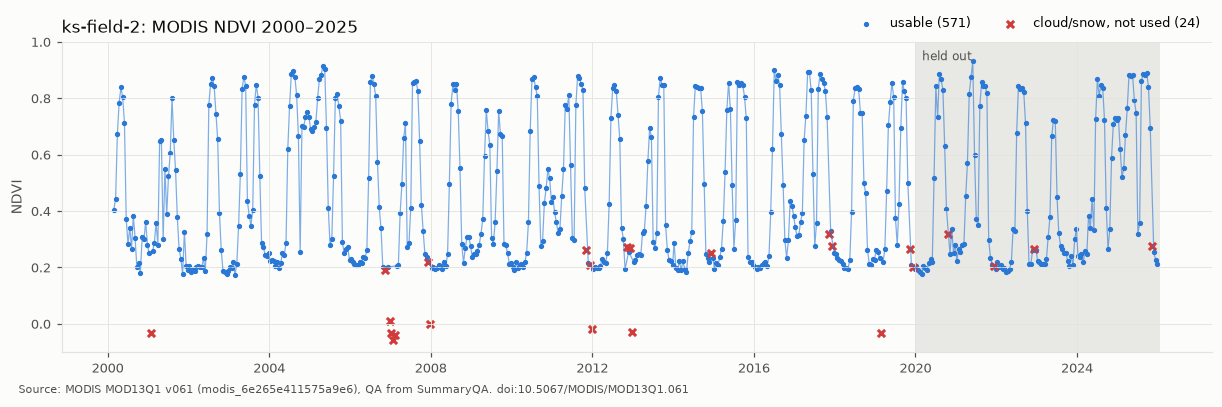

In [3]:
c = comps.copy()
c["d"] = pd.to_datetime(c.composite_start) + pd.Timedelta(days=8)
fig, ax = plt.subplots(figsize=(11, 3.4), constrained_layout=True)
ok = c[c.qa_pass]
bad = c[~c.qa_pass & c.ndvi.notna()]
ax.axvspan(HELD_OUT_START, c.d.max() + pd.Timedelta(days=20), color=GRID, alpha=0.8, lw=0)
ax.text(HELD_OUT_START + pd.Timedelta(days=60), 0.97, "held out", fontsize=8, color=INK2, va="top")
ax.plot(ok.d, ok.ndvi, color=BLUE, lw=0.8, alpha=0.6)
ax.scatter(ok.d, ok.ndvi, s=6, color=BLUE, label=f"usable ({len(ok)})")
ax.scatter(bad.d, bad.ndvi, s=22, marker="x", color=CRITICAL, label=f"cloud/snow, not used ({len(bad)})")
ax.set_ylim(-0.1, 1)
ax.set_ylabel("NDVI")
ax.set_title(f"{SITE}: MODIS NDVI 2000–2025")
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2)
caption(fig, f"Source: MODIS MOD13Q1 v061 ({modis_id}), QA from SummaryQA. doi:10.5067/MODIS/MOD13Q1.061")
plt.show()

## 3 · How a season is found

1. Drop unusable composites. Bridge gaps of at most two composites (32 days) and flag them. Longer gaps split the
   series.
2. Smooth with a Savitzky–Golay filter.
3. Each peak with prominence ≥ 0.1 NDVI is a season. **Start** and **end** are where the curve crosses a set fraction
   of that season's rise and fall (the TIMESAT amplitude-threshold method). Two seasons in one year are allowed.

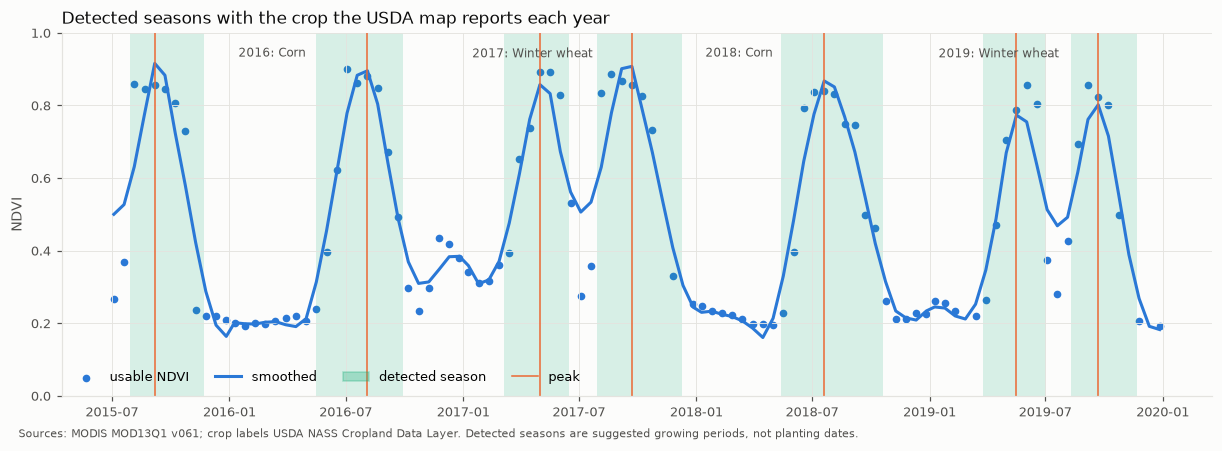

In [4]:
res = ss.result
ser = res.series.copy()
ser["date"] = pd.to_datetime(ser["date"])
w0, w1 = pd.Timestamp("2015-07-01"), pd.Timestamp("2019-12-31")
win = ser[(ser.date >= w0) & (ser.date <= w1)]
fig, ax = plt.subplots(figsize=(11, 3.8), constrained_layout=True)
ax.scatter(win.date, win.ndvi_qa, s=16, color=BLUE, label="usable NDVI")
ax.plot(win.date, win.ndvi_smooth, color=BLUE, label="smoothed")
for s in res.seasons:
    pk = pd.Timestamp(s.peak)
    if not (w0 <= pk <= w1):
        continue
    if s.start and s.end:
        ax.axvspan(pd.Timestamp(s.start), pd.Timestamp(s.end), color=AQUA, alpha=0.16, lw=0)
    ax.axvline(pk, color=ORANGE, lw=1)
for y in range(2016, 2020):
    ax.text(pd.Timestamp(f"{y}-01-15"), 0.96, f"{y}: {history.get(y, '?')}", fontsize=8, color=INK2, va="top")
from matplotlib.patches import Patch  # noqa: E402

ax.legend(
    handles=[
        *ax.get_legend_handles_labels()[0],
        Patch(color=AQUA, alpha=0.3, label="detected season"),
        plt.Line2D([], [], color=ORANGE, lw=1, label="peak"),
    ],
    loc="lower left",
    ncol=4,
)
ax.set_ylim(0, 1)
ax.set_ylabel("NDVI")
ax.set_title("Detected seasons with the crop the USDA map reports each year")
caption(
    fig,
    "Sources: MODIS MOD13Q1 v061; crop labels USDA NASS Cropland Data Layer. Detected seasons are "
    "suggested growing periods, not planting dates.",
)
plt.show()

## 4 · Corn years vs wheat years: why two seasons

Overlaying each year's curve by day of year makes the rotation visible. **Corn years** have one summer peak.
**Wheat years** have a spring wheat peak, a harvest drop in July, and a second green-up in August–September. The
USDA map itself labels 2011 and 2013 "double crop winter wheat / sorghum". This is why the method allows two
seasons a year.

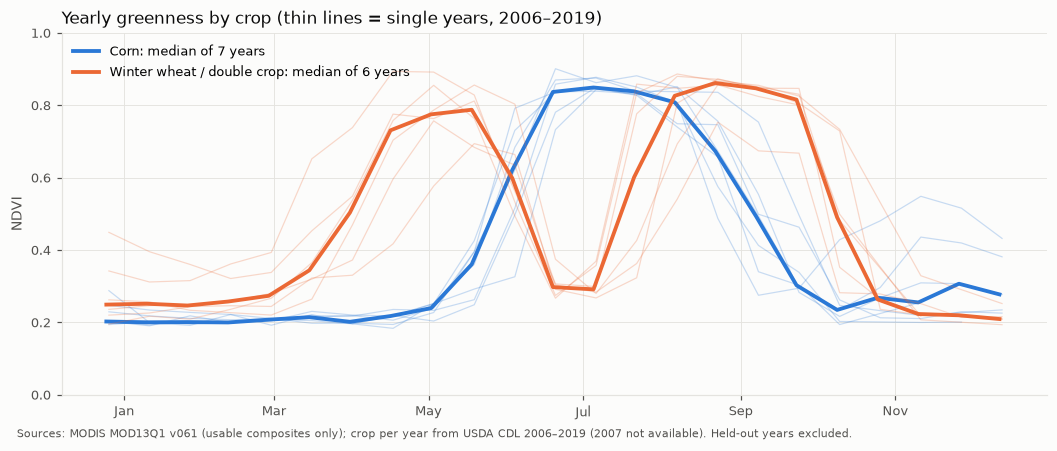

In [5]:
c["year"] = [d.year for d in c.composite_start]
c["doy"] = c.d.dt.day_of_year
groups = {
    "Corn": [y for y, v in history.items() if v == "Corn" and y < 2020],
    "Winter wheat / double crop": [
        y for y, v in history.items() if (v == "Winter wheat" or v.startswith("Dbl")) and y < 2020
    ],
}
fig, ax = plt.subplots(figsize=(9.5, 3.8), constrained_layout=True)
for (label, years), color in zip(groups.items(), (BLUE, ORANGE), strict=True):
    g = c[c.year.isin(years) & c.qa_pass]
    for _y, gy in g.groupby("year"):
        ax.plot(gy.doy, gy.ndvi, color=color, lw=0.8, alpha=0.25)
    med = g.groupby((g.doy // 16) * 16 + 8).ndvi.median()
    ax.plot(med.index, med.values, color=color, lw=2.5, label=f"{label}: median of {len(years)} years")
ax.set_xticks([15, 74, 135, 196, 258, 319], ["Jan", "Mar", "May", "Jul", "Sep", "Nov"])
ax.set_ylim(0, 1)
ax.set_ylabel("NDVI")
ax.set_title("Yearly greenness by crop (thin lines = single years, 2006–2019)")
ax.legend(loc="upper left")
caption(
    fig,
    "Sources: MODIS MOD13Q1 v061 (usable composites only); crop per year from USDA CDL 2006–2019 "
    "(2007 not available). Held-out years excluded.",
)
plt.show()

## 5 · Tuning and evaluation against USDA planting dates

**Reference:** USDA NASS Crop Progress, the date Kansas reached **50 % planted**, for the crop the USDA map reports
that year. Only spring-planted summer crops can be scored (winter wheat is sown in autumn but greens up in spring).
**Tuning:** the 18 settings declared in advance, on 2006–2014. **Check:** 2015–2019 without retuning.

In [6]:
comps_pre = comps[[d.year < 2020 for d in comps.composite_start]]
tune_refs, tune_rows = references(history, TUNING_YEARS)
dev_refs, dev_rows = references(history, DEV_YEARS)
val = ss.validations[0]
record_path = get_settings().results_dir / "validation" / f"phenology_{SITE}.json"
with open(record_path, encoding="utf-8") as fh:
    table = pd.DataFrame(json.load(fh)["tuning_table"])
print("Pre-declared grid:", TUNING_GRID)
display(
    table.sort_values("median_abs_error_days")[
        ["window", "polyorder", "fraction", "detection_rate", "bias_days", "median_abs_error_days"]
    ].head(8)
)
print("Chosen:", ss.result.params, "| validation record:", val.id)

Pre-declared grid: {'window': (5, 7, 9), 'polyorder': (2, 3), 'fraction': (0.2, 0.3, 0.5)}


,window,polyorder,fraction,detection_rate,bias_days,median_abs_error_days
0,9,2,0.2,1.0,22.4,20.0
1,9,3,0.2,1.0,22.4,20.0
2,7,2,0.2,1.0,28.2,26.0
3,7,3,0.2,1.0,28.2,26.0
4,9,2,0.3,1.0,30.4,29.0
5,9,3,0.3,1.0,30.4,29.0
6,5,2,0.2,1.0,32.0,30.0
7,5,3,0.2,1.0,32.0,30.0


Chosen: PhenologyParams(window=9, polyorder=2, fraction=0.2) | validation record: val_phenology_ks-field-2_20261114T122511Z


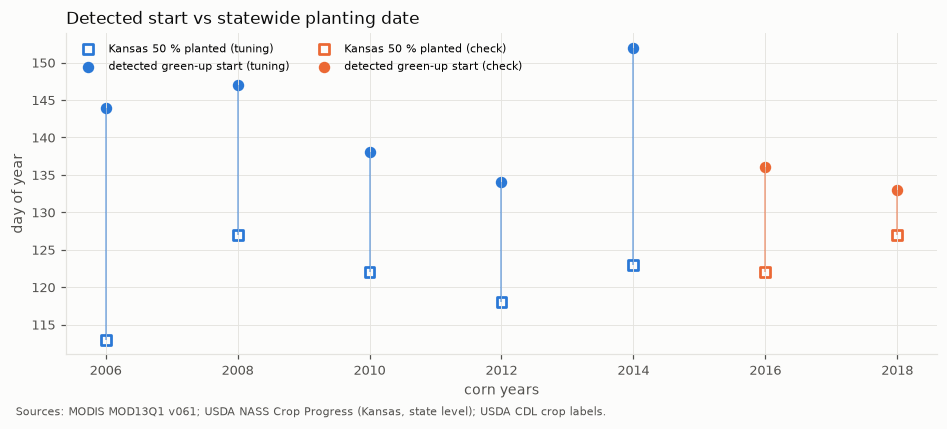

,year,split,reference,detected,error_days
0,2006,tuning,2006-04-23,2006-05-24,31
1,2008,tuning,2008-05-06,2008-05-26,20
2,2010,tuning,2010-05-02,2010-05-18,16
3,2012,tuning,2012-04-27,2012-05-13,16
4,2014,tuning,2014-05-03,2014-06-01,29
5,2016,check,2016-05-01,2016-05-15,14
6,2018,check,2018-05-07,2018-05-13,6


Tuning: n=5, bias +22.4 d, median |error| 20 d | Check: n=2, bias +10.0 d
Recorded failures: ['development check has only n=2 scored season(s): too few to judge']


In [7]:
pre = detect_seasons(comps_pre, ss.result.params)
rows = []
for r in tune_rows + dev_rows:
    det = next((s for s in pre.seasons if s.peak.year == r["year"] and s.peak.month in PEAK_MONTHS and s.start), None)
    if r["reference"] and det:
        rows.append(
            {
                "year": r["year"],
                "split": "tuning" if r["year"] in TUNING_YEARS else "check",
                "reference": r["reference"],
                "detected": det.start,
                "error_days": (det.start - r["reference"]).days,
            }
        )
ev = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.6), constrained_layout=True)
for split, color in (("tuning", BLUE), ("check", ORANGE)):
    g = ev[ev.split == split]
    ref_doy = [pd.Timestamp(x).day_of_year for x in g.reference]
    det_doy = [pd.Timestamp(x).day_of_year for x in g.detected]
    ax.vlines(g.year, ref_doy, det_doy, color=color, lw=1, alpha=0.6)
    ax.scatter(
        g.year,
        ref_doy,
        marker="s",
        s=42,
        facecolor="none",
        edgecolor=color,
        linewidth=1.8,
        label=f"Kansas 50 % planted ({split})",
    )
    ax.scatter(g.year, det_doy, s=42, color=color, label=f"detected green-up start ({split})")
ax.set_ylabel("day of year")
ax.set_xlabel("corn years")
ax.legend(ncol=2, loc="upper left", fontsize=7.5)
ax.set_title("Detected start vs statewide planting date")
caption(fig, "Sources: MODIS MOD13Q1 v061; USDA NASS Crop Progress (Kansas, state level); USDA CDL crop labels.")
plt.show()
display(ev)
m = val.metrics
print(
    f"Tuning: n={int(m['tuning_n'])}, bias {m['tuning_bias_days']:+.1f} d, "
    f"median |error| {m['tuning_median_abs_error_days']:.0f} d | "
    f"Check: n={int(m['dev_n'])}, bias {m['dev_bias_days']:+.1f} d"
)
print("Recorded failures:", val.failures)

**Reading it**
- Every scored corn season was found.
- The satellite start comes **2–3 weeks after the statewide planting date**. That's expected: corn must emerge and
  grow leaves before it shows from space. The app must call this *green-up*, not planting.
- The check years agree more closely without retuning, which argues against overfitting.

**Limits**
- n = 5 (tuning) and n = 2 (check): too few to judge the check, and that's recorded as a failure.
- The reference is statewide, not this field.
- The chosen fraction (0.2) is at the edge of the declared grid. The grid is not widened after seeing results.
- Wheat and double-crop starts are not validated.

## 6 · What goes to the app and to M4

In [8]:
from ftm.data.journey import build_journey

for st in build_journey(SITE, session):
    if st.stage.value in ("extract", "validate"):
        print(f"[{st.stage.value} · {st.status.value}] {st.summary}")
lc = [(a, b) for a, b in ss.result.low_cover_windows if b.year < 2020]
print(
    f"\nSeasons before 2020: {sum(s.peak.year < 2020 for s in ss.result.seasons)} | "
    f"low-cover windows before 2020: {len(lc)}"
)
print("Example low-cover windows (between detected seasons):", lc[-3:])
session.close()

[extract · ok] 38 suggested growing periods detected from satellite greenness.
[validate · warning] Season starts checked against USDA NASS Crop Progress: found 5 of 5 tuning seasons; detected green-up is on average +22 days after the statewide planting date. Development check: n = 2.

Seasons before 2020: 29 | low-cover windows before 2020: 28
Example low-cover windows (between detected seasons): [(datetime.date(2017, 12, 10), datetime.date(2018, 5, 13)), (datetime.date(2018, 10, 20), datetime.date(2019, 3, 26)), (datetime.date(2019, 7, 2), datetime.date(2019, 8, 11))]


- **M4 (engine):** `ftm.validation.site_seasons.get_site_seasons(site_id, session)` returns the seasons and
  low-cover windows with the tuned settings. Use them as **evidence** next to the crop calendar, never as planting
  dates. Wheat years may need a summer crop after harvest.
- **UI wording:** "suggested growing period", "green-up", "possible low vegetation cover". Never "planting date",
  "bare soil" or a crop name from the satellite alone.
- **Next:** the held-out 2020–2025 check runs once, at feature freeze.